In [1]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#loading the required dataset 
carfuel_df = pd.read_csv("car_fuel_efficiency_2026.csv")
carfuel_df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [3]:
# feature selection for downstream processes 
carfuel_df = carfuel_df[['engine_displacement',
'horsepower',
'vehicle_weight',
'model_year',
'fuel_efficiency_mpg']]

carfuel_df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


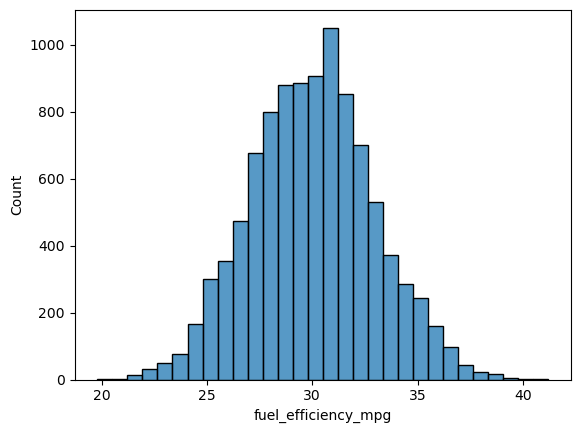

In [4]:
#doing exploratory data analysis (EDA)
sns.histplot(carfuel_df["fuel_efficiency_mpg"],bins = 30);#checking the target value has long tail or not

In [5]:
#checking the feature selected dataset for missing values
carfuel_df.isna().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [6]:
#finding the 50% percentile of horsepower
carfuel_df.horsepower.median()

254.0

In [7]:
def data_split(df,fill = 0,seed = 42):
    df_new = df.copy()

    df_new = df_new.fillna(fill)
    n = len(df)
    n_train = int(0.6 * n)
    n_val = int(0.2*(n))
    n_test = int(0.2* (n))

    idx = np.arange(n)
    np.random.seed(seed)
    np.random.shuffle(idx)

    train_set = df_new.iloc[idx[:n_train]]
    val_set = df_new.iloc[idx[n_train:n_train+n_val]]
    test_set = df_new.iloc[idx[n_train+n_val:]]

    train_set = train_set.reset_index(drop=True)
    val_set = val_set.reset_index(drop=True)
    test_set = test_set.reset_index(drop=True)

    X_train = train_set.drop(columns='fuel_efficiency_mpg')
    y_train = train_set[['fuel_efficiency_mpg']]

    X_val = val_set.drop(columns='fuel_efficiency_mpg')
    y_val = val_set[['fuel_efficiency_mpg']]

    X_test = test_set.drop(columns='fuel_efficiency_mpg')
    y_test = test_set[['fuel_efficiency_mpg']]

    return X_train,y_train,X_val,y_val,X_test,y_test


In [8]:
def linear_regression(X,y):

    X_we = X.values
    ones = np.ones(X.shape[0])
    X_we = np.column_stack([ones,X_we])
    y_we = y.values
    XTX = np.dot(X_we.T,X_we)
    XTX_inv = np.linalg.inv(XTX)
    weights = XTX_inv.dot(X_we.T).dot(y_we)
    w0,w1 = weights[0],weights[1:]
    return w0,w1

In [9]:
def rmse(pred,y):
    
    mse = np.sum(((pred - y) ** 2))/y.shape[0]
    rmse = np.sqrt(mse)

    return rmse

In [10]:
#rmse with fillna(0)
X_train,y_train,X_val,y_val,X_test,y_test = data_split(carfuel_df,seed = 9)

w0,w1 = linear_regression(X_train,y_train)
predictions = w0 + np.dot(X_val,w1)

rmse_na = rmse(predictions,y_val)
print(round(rmse_na,3))

fuel_efficiency_mpg    2.207
dtype: float64


C:\Users\User\anaconda3\anonconda\anaconda\Lib\site-packages\numpy\core\fromnumeric.py:86: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


In [11]:
#rmse with fillna(mean)
mean = X_train.mean()
# mean = int(mean)
X_train_set,y_train_set,X_val_set,y_val_set,X_test_set,y_test_set = data_split(carfuel_df,fill = mean)

w0_m,w1_m = linear_regression(X_train_set,y_train_set)
predictions_mean = w0_m + np.dot(X_val_set,w1_m)

rmse_mean = rmse(predictions_mean,y_val_set)
print(round(rmse_mean,3))

fuel_efficiency_mpg    2.201
dtype: float64


C:\Users\User\anaconda3\anonconda\anaconda\Lib\site-packages\numpy\core\fromnumeric.py:86: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


In [12]:
def linear_regression_reg(X,y,r):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones,X])

    XTX = X.T.dot(X)
    eyes = np.eye(XTX.shape[0])
    XTX = XTX + r * eyes

    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)

    w0,w1 = w[0],w[1:]

    return w0,w1

In [13]:
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0,w1 = linear_regression_reg(X_train,y_train,r)
    predictions = w0 +  np.dot(X_val,w1)
    rmse_reg = rmse(predictions,y_val)

    print("rmse_{}:  {}".format(r,round(rmse_reg,4)))
    

rmse_0:  fuel_efficiency_mpg    2.207
dtype: float64
rmse_0.01:  fuel_efficiency_mpg    2.2067
dtype: float64
rmse_0.1:  fuel_efficiency_mpg    2.2195
dtype: float64
rmse_1:  fuel_efficiency_mpg    2.3364
dtype: float64
rmse_5:  fuel_efficiency_mpg    2.3952
dtype: float64
rmse_10:  fuel_efficiency_mpg    2.4051
dtype: float64
rmse_100:  fuel_efficiency_mpg    2.4146
dtype: float64


In [14]:
rmse_seed = {}
for seed in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:
    X_train_sed,y_train_sed,X_val_sed,y_val_sed,X_test_sed,y_test_sed = data_split(carfuel_df,seed=seed)
    w0_seed,w1_seed = linear_regression(X_train_sed,y_train_sed)
    predictions_seed = w0_seed + np.dot(X_val_sed,w1_seed)

    rmse_sed = rmse(predictions_seed,y_val_sed)
    rmse_seed[f"seed_{seed}"] = float(rmse_sed)
print(rmse_seed)

{'seed_0': 2.239204143046126, 'seed_1': 2.2021128210838845, 'seed_2': 2.1634197787530947, 'seed_3': 2.2043588768539224, 'seed_4': 2.2018800943311554, 'seed_5': 2.2457851509085134, 'seed_6': 2.2697212079524043, 'seed_7': 2.190794599933443, 'seed_8': 2.216611201686444, 'seed_9': 2.2070365928178957}


C:\Users\User\anaconda3\anonconda\anaconda\Lib\site-packages\numpy\core\fromnumeric.py:86: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)
C:\Users\User\AppData\Local\Temp\ipykernel_13820\2543151362.py:8: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  rmse_seed[f"seed_{seed}"] = float(rmse_sed)
C:\Users\User\anaconda3\anonconda\anaconda\Lib\site-packages\numpy\core\fromnumeric.py:86: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)
C:\Users\User\AppData\Local\Temp\ipyk

In [15]:
list(rmse_seed.values())

[2.239204143046126,
 2.2021128210838845,
 2.1634197787530947,
 2.2043588768539224,
 2.2018800943311554,
 2.2457851509085134,
 2.2697212079524043,
 2.190794599933443,
 2.216611201686444,
 2.2070365928178957]

In [16]:
std = np.std(list(rmse_seed.values()))
print(round(std,3))

0.029


In [17]:
#question 6, seed = 9, with regularization
X_train_9,y_train_9,X_val_9,y_val_9,X_test_9,y_test_9 = data_split(carfuel_df,seed=9)
X_train_full = pd.concat([X_train_9,X_val_9],axis=0)
y_train_full = pd.concat([y_train_9,y_val_9],axis=0)

w0_9,w1_9 = linear_regression_reg(X_train_full,y_train_full,r = 0.001)
predictions_9 = w0_9 + np.dot(X_test_9,w1_9)
rmse_9 = rmse(predictions_9,y_test_9)
print(round(rmse_9,3))

fuel_efficiency_mpg    2.236
dtype: float64


C:\Users\User\anaconda3\anonconda\anaconda\Lib\site-packages\numpy\core\fromnumeric.py:86: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)
